https://www.kaggle.com/code/parulpandey/exploratory-data-analysis-of-the-emotion-dataset

# Importing libraries

In [11]:
import numpy as np
import pandas as pd
import string

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.2)
colors = ["#01BEFE", "#FFDD00", "#FF7D00", "#FF006D", "#ADFF02", "#8F00FF"]
sns.set_palette(sns.color_palette(colors))
matplotlib.rcParams['figure.figsize'] = 10, 5

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Importing data

In [2]:
# Loading data from Hugging face datasets
splits = {'train': 'split/train-00000-of-00001.parquet',
          'validation': 'split/validation-00000-of-00001.parquet',
          'test': 'split/test-00000-of-00001.parquet'}

train_df = pd.read_parquet("hf://datasets/dair-ai/emotion/" + splits["train"])
val_df = pd.read_parquet("hf://datasets/dair-ai/emotion/" + splits["validation"])
test_df = pd.read_parquet("hf://datasets/dair-ai/emotion/" + splits["test"])

In [3]:
train_df.columns

Index(['text', 'label'], dtype='object')

In [4]:
# Get the id to label equivalence from : https://huggingface.co/datasets/dair-ai/emotion
id2label = {
    0 : "sadness",
    1 : "joy",
    2 : "love",
    3 : "anger",
    4 : "fear",
    5 : "surprise"
}

label2id = {e : i for e, i in id2label.items()}

In [5]:
# Add description columns in dataframes
train_df['description'] = train_df['label'].map(id2label)
val_df['description'] = val_df['label'].map(id2label)
test_df['description'] = test_df['label'].map(id2label)

In [6]:
train_df.head()

,text,label,description
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger


# Distribution

In [7]:
train_df.description.value_counts(normalize=True)

description
joy         0.335125
sadness     0.291625
anger       0.134937
fear        0.121063
love        0.081500
surprise    0.035750
Name: proportion, dtype: float64

In [8]:
val_df.description.value_counts(normalize=True)

description
joy         0.3520
sadness     0.2750
anger       0.1375
fear        0.1060
love        0.0890
surprise    0.0405
Name: proportion, dtype: float64

In [9]:
test_df.description.value_counts(normalize=True)

description
joy         0.3475
sadness     0.2905
anger       0.1375
fear        0.1120
love        0.0795
surprise    0.0330
Name: proportion, dtype: float64

<Axes: xlabel='count', ylabel='description'>

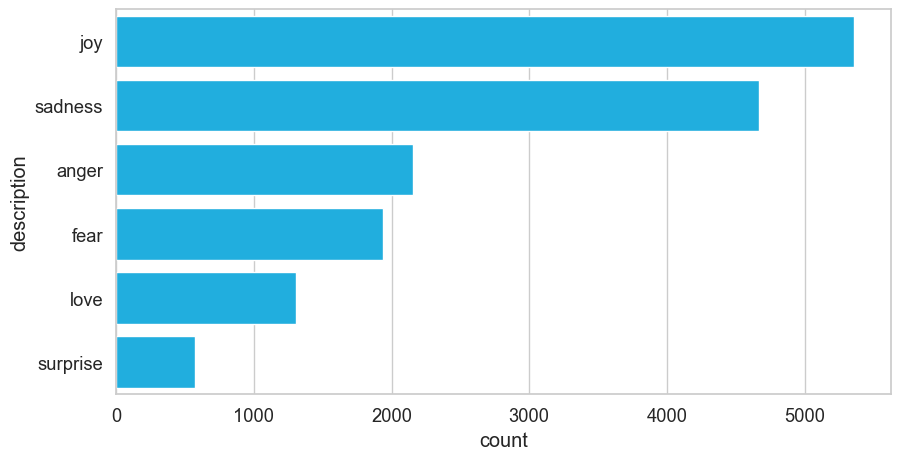

In [12]:
sns.countplot(train_df['description'], order=train_df['description'].value_counts(normalize=True).index)

The labels distribution is the same for each data set split \\


In [13]:
train_df['text_length'] = train_df['text'].astype(str).apply(len)
train_df['text_word_count'] = train_df['text'].apply(lambda x: len(str(x).split()))

Text(0.5, 0, 'Text Length')

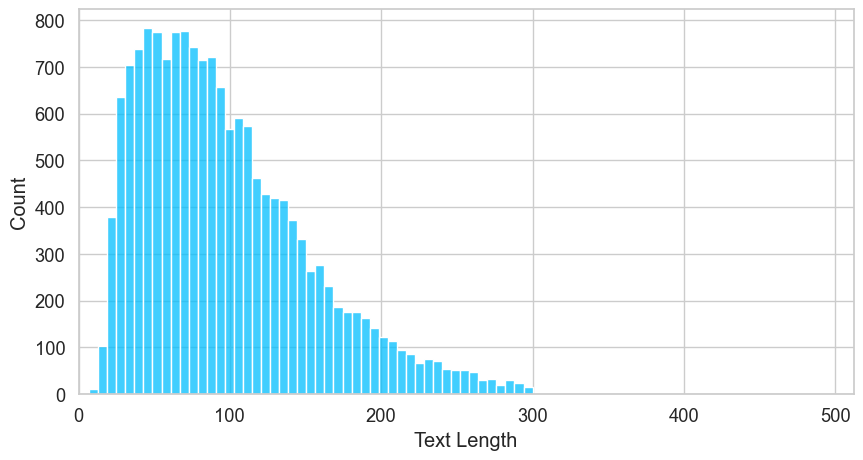

In [17]:
sns.histplot(train_df['text_length'])
plt.xlim([0, 512])
plt.xlabel('Text Length')

<Axes: xlabel='description', ylabel='text_word_count'>

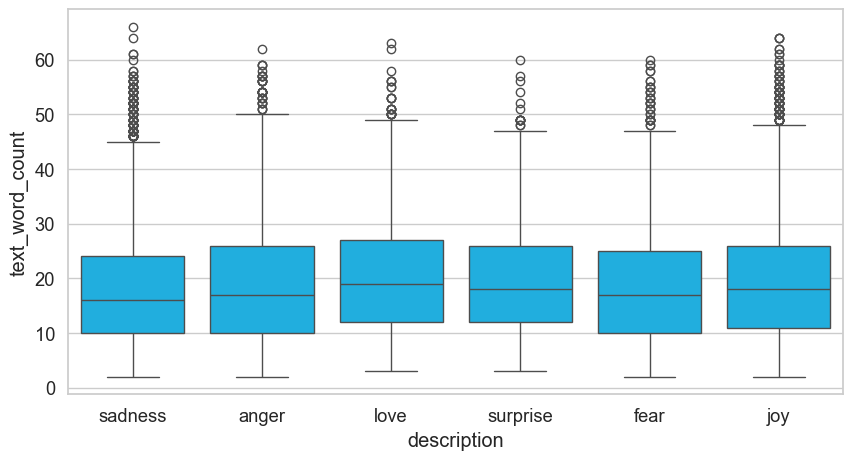

In [18]:
sns.boxplot(x="description", y="text_word_count", data=train_df)

In [19]:
# Creating individual dataframes of different emotions
sadness = train_df[train_df['label']==0]['text']
joy = train_df[train_df['label']==1]['text']
love = train_df[train_df['label']==2]['text']
anger = train_df[train_df['label']==3]['text']
fear = train_df[train_df['label']==4]['text']
surprise = train_df[train_df['label']==5]['text']

In [20]:
# Code to calculate ngrams
# source of code : https://medium.com/@cristhianboujon/how-to-list-the-most-common-words-from-text-corpus-using-scikit-learn-dad4d0cab41d

from sklearn.feature_extraction.text import CountVectorizer

def get_top_n_gram(corpus,ngram_range,n=None):
    vec = CountVectorizer(ngram_range=ngram_range,stop_words = 'english').fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq =sorted(words_freq, key = lambda x: x[1], reverse=True)
    return words_freq[:n]

In [21]:
# calculating unigrmas, bigrams and trigrams for all given emotions

sad_unigrams = get_top_n_gram(sadness.values,(1,1),7)[2:]
joy_unigrams= get_top_n_gram(joy.values,(1,1),7)[2:]
love_unigrams= get_top_n_gram(love.values,(1,1),7)[2:]
anger_unigrams= get_top_n_gram(anger.values,(1,1),7)[2:]
fear_unigrams= get_top_n_gram(fear.values,(1,1),7)[2:]
surprise_unigrams= get_top_n_gram(surprise.values,(1,1),7)[2:]



sad_bigrams = get_top_n_gram(sadness.values,(2,2),7)[2:]
joy_bigrams= get_top_n_gram(joy.values,(2,2),7)[2:]
love_bigrams= get_top_n_gram(love.values,(2,2),7)[2:]
anger_bigrams= get_top_n_gram(anger.values,(2,2),7)[2:]
fear_bigrams= get_top_n_gram(fear.values,(2,2),7)[2:]
surprise_bigrams= get_top_n_gram(surprise.values,(2,2),7)[2:]


sad_trigrams = get_top_n_gram(sadness.values,(3,3),7)[2:]
joy_trigrams= get_top_n_gram(joy.values,(3,3),7)[2:]
love_trigrams= get_top_n_gram(love.values,(3,3),7)[2:]
anger_trigrams= get_top_n_gram(anger.values,(3,3),7)[2:]
fear_trigrams= get_top_n_gram(fear.values,(3,3),7)[2:]
surprise_trigrams= get_top_n_gram(surprise.values,(3,3),7)[2:]

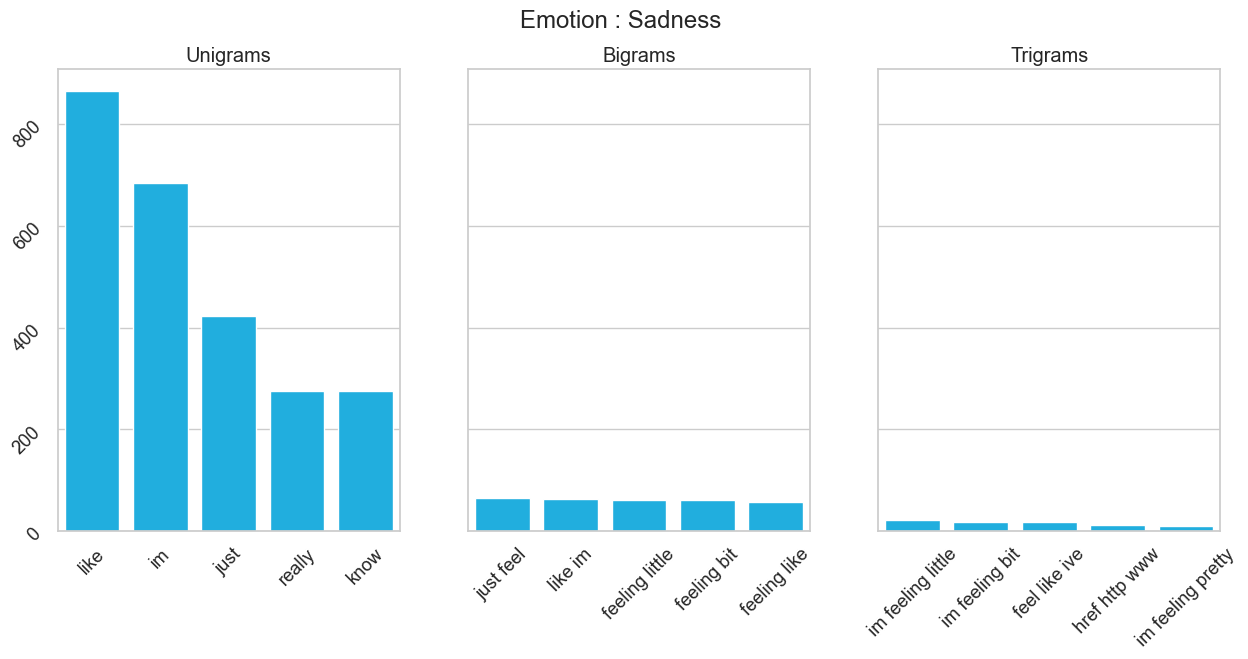

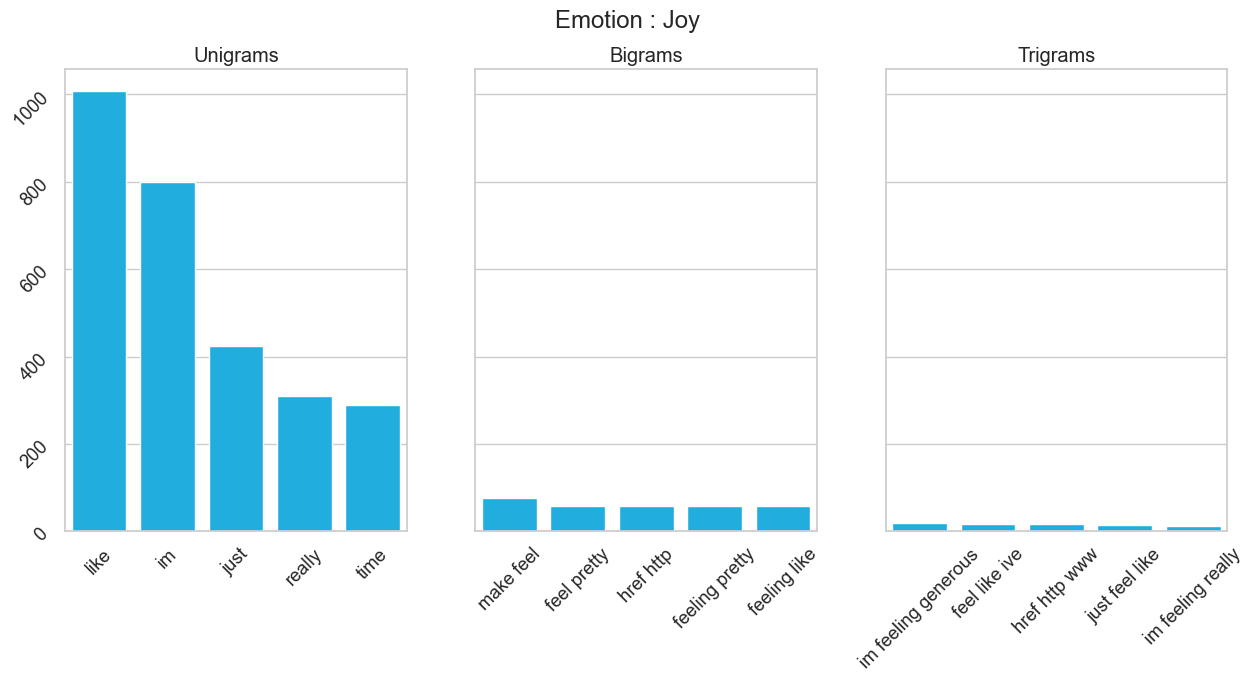

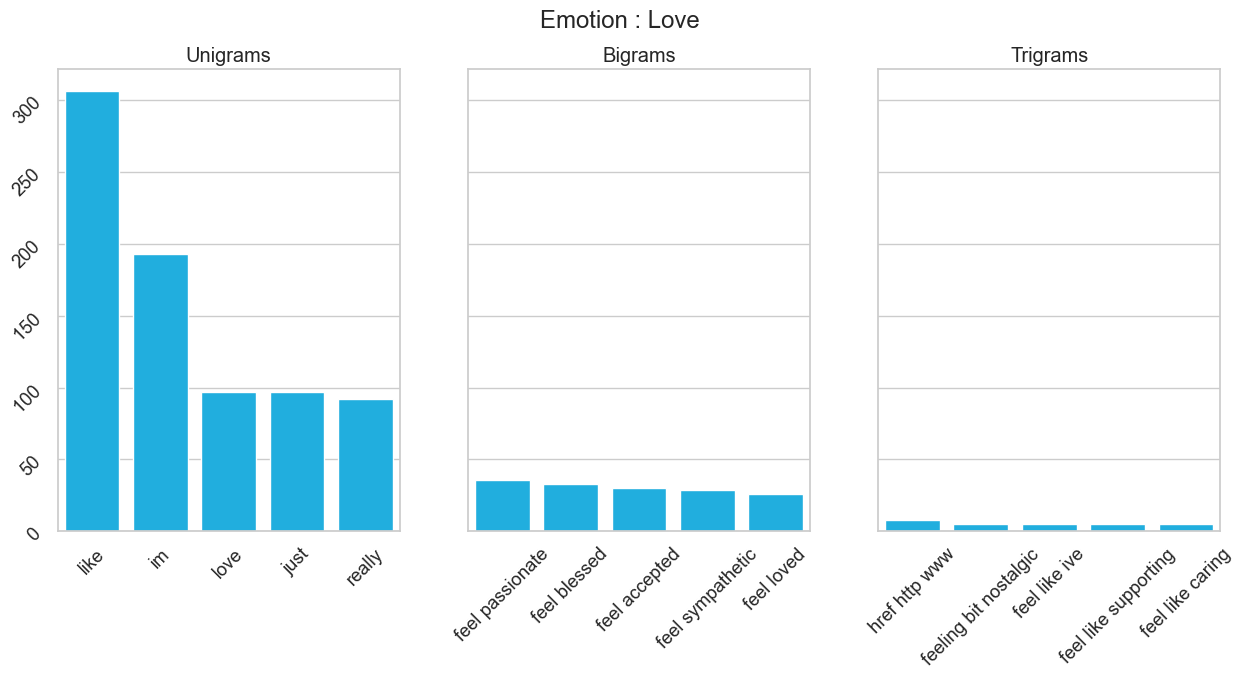

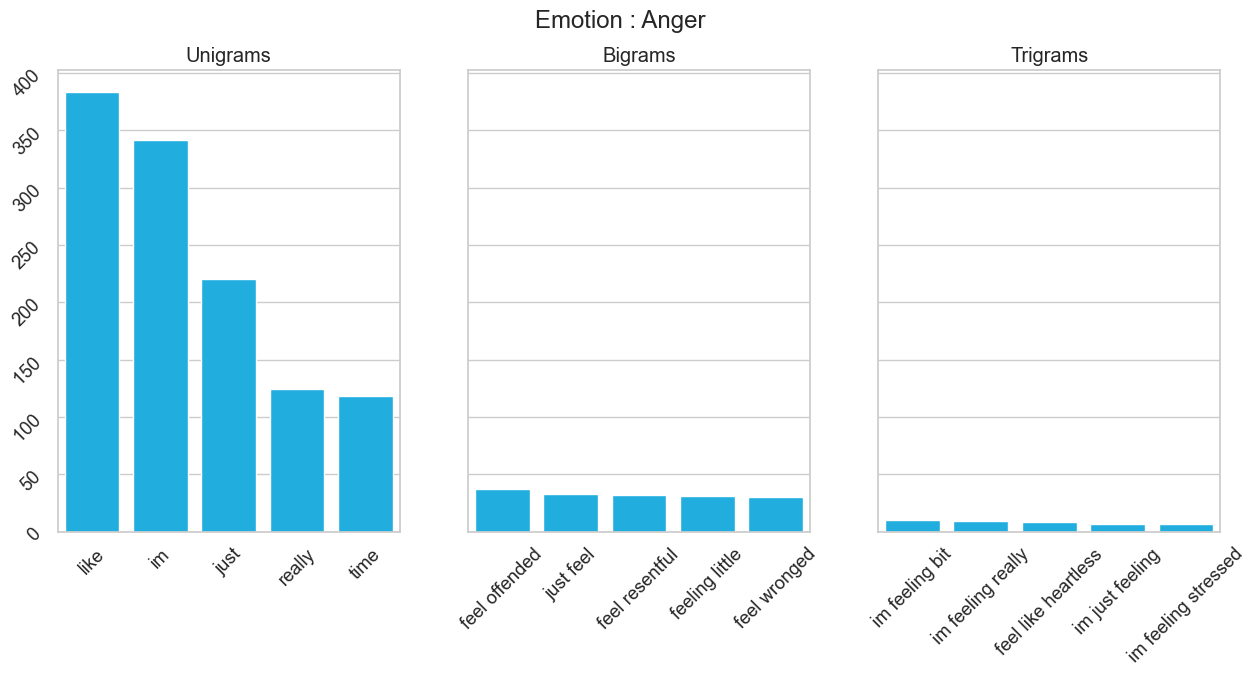

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
fig.suptitle('Emotion : Sadness')



sns.barplot(x=list(dict(sad_unigrams).keys()), y=list(dict(sad_unigrams).values()),ax=axes[0])
axes[0].set_title('Unigrams')
axes[0].tick_params(labelrotation=45)



sns.barplot(x=list(dict(sad_bigrams).keys()), y=list(dict(sad_bigrams).values()),ax=axes[1])
axes[1].set_title('Bigrams')
axes[1].tick_params(labelrotation=45)



sns.barplot( x=list(dict(sad_trigrams).keys()), y=list(dict(sad_trigrams).values()),ax=axes[2],)
axes[2].set_title('Trigrams')
axes[2].tick_params(labelrotation=45)


#Joy

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
fig.suptitle('Emotion : Joy')

sns.barplot( x=list(dict(joy_unigrams).keys()), y=list(dict(joy_unigrams).values()),ax=axes[0],)
axes[0].set_title('Unigrams')
axes[0].tick_params(labelrotation=45)

sns.barplot( x=list(dict(joy_bigrams).keys()), y=list(dict(joy_bigrams).values()),ax=axes[1],)
axes[1].set_title('Bigrams')
axes[1].tick_params(labelrotation=45)


sns.barplot( x=list(dict(joy_trigrams).keys()), y=list(dict(joy_trigrams).values()),ax=axes[2],)
axes[2].set_title('Trigrams')
axes[2].tick_params(labelrotation=45)

#Love

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
fig.suptitle('Emotion : Love')

sns.barplot( x=list(dict(love_unigrams).keys()), y=list(dict(love_unigrams).values()),ax=axes[0],)
axes[0].set_title('Unigrams')
axes[0].tick_params(labelrotation=45)

sns.barplot( x=list(dict(love_bigrams).keys()), y=list(dict(love_bigrams).values()),ax=axes[1],)
axes[1].set_title('Bigrams')
axes[1].tick_params(labelrotation=45)



sns.barplot( x=list(dict(love_trigrams).keys()), y=list(dict(love_trigrams).values()),ax=axes[2],)
axes[2].set_title('Trigrams')
axes[2].tick_params(labelrotation=45)


#Anger
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
fig.suptitle('Emotion : Anger')

sns.barplot( x=list(dict(anger_unigrams).keys()), y=list(dict(anger_unigrams).values()),ax=axes[0],)
axes[0].set_title('Unigrams')
axes[0].tick_params(labelrotation=45)

sns.barplot( x=list(dict(anger_bigrams).keys()), y=list(dict(anger_bigrams).values()),ax=axes[1],)
axes[1].set_title('Bigrams')
axes[1].tick_params(labelrotation=45)



sns.barplot( x=list(dict(anger_trigrams).keys()), y=list(dict(anger_trigrams).values()),ax=axes[2],)
axes[2].set_title('Trigrams')
axes[2].tick_params(labelrotation=45)